# Music Genre Classification on GTZAN

**Goal:** classify 30-second music clips into 10 genres (blues, classical, country, disco, hiphop, jazz, metal, pop, reggae, rock).

We compare **three approaches on exactly the same train / validation / test split**:

| # | Approach | Input | Model |
|---|----------|-------|-------|
| A | Tabular | Hand-crafted librosa features (MFCCs, chroma, spectral stats, tempo...) | Logistic Regression, kNN, SVM, Random Forest, HistGradientBoosting, MLP |
| B | Image-based | Mel-spectrograms (128x128) | CNN trained from scratch (Keras) |
| C | Transfer learning | Same mel-spectrograms | ImageNet-pretrained MobileNetV2 (frozen head, then fine-tuned) |

### Important design choices
* **Each 30 s track is cut into ten 3 s segments** (10x more training samples).
* **The split is done by *track*, never by segment.** Segments of one song are very similar, so a random split over segments leaks the same song into train and test and gives inflated accuracy (this is a common mistake with the Kaggle `features_3_sec.csv`).
* We report both **segment-level** accuracy and **track-level** accuracy (average the probabilities of a track's 10 segments, then take the argmax).
* Audio is decoded **once** per track; tabular features and spectrograms are both produced in that pass and cached to disk.

> Run on Kaggle / Colab with a GPU for parts B and C. Part A only needs a CPU.

## 0. Setup

In [1]:
%pip install -q librosa kagglehub seaborn

In [2]:
import os, glob, random, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")

# ---- audio / spectrogram configuration ----
SR = 22050              # sample rate
SEG_SECONDS = 3         # segment length
N_SEGS = 10             # segments per 30 s track
SEG_LEN = SR * SEG_SECONDS
N_FFT, HOP, N_MELS = 2048, 512, 128
N_FRAMES = 128          # crop the ~130 time frames to 128 -> 128x128 "image"

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load the dataset
The notebook looks for the Kaggle dataset `andradaolteanu/gtzan-dataset-music-genre-classification` under `/kaggle/input`; if it is not there (e.g. on Colab) it downloads it with `kagglehub`.
(For `kagglehub` you may need Kaggle credentials: set `KAGGLE_USERNAME` / `KAGGLE_KEY`, or place `kaggle.json` in `~/.kaggle`.)

To use your own copy, set `AUDIO_ROOT` manually to the folder that contains the 10 genre sub-folders.

In [3]:
def find_audio_root():
    hits = glob.glob("/kaggle/input/**/genres_original", recursive=True)
    if hits:
        return hits[0]
    import kagglehub
    root = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")
    hits = glob.glob(os.path.join(root, "**", "genres_original"), recursive=True)
    assert hits, "Could not find 'genres_original' - set AUDIO_ROOT manually."
    return hits[0]

AUDIO_ROOT = find_audio_root()          # <- or set it yourself
GENRES = sorted(d for d in os.listdir(AUDIO_ROOT) if os.path.isdir(os.path.join(AUDIO_ROOT, d)))
G2I = {g: i for i, g in enumerate(GENRES)}

rows = []
for g in GENRES:
    for p in sorted(glob.glob(os.path.join(AUDIO_ROOT, g, "*.wav"))):
        rows.append((p, g, G2I[g]))
df_tracks = pd.DataFrame(rows, columns=["path", "genre", "label"])
print(AUDIO_ROOT)
print(len(df_tracks), "tracks")
df_tracks.genre.value_counts().sort_index()

100%|██████████| 1.21G/1.21G [01:09<00:00, 18.6MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/genres_original
1000 tracks


,count
genre,
blues,100
classical,100
country,100
disco,100
hiphop,100
jazz,100
metal,100
pop,100
reggae,100


### Peek at the data: waveform and mel-spectrogram per genre

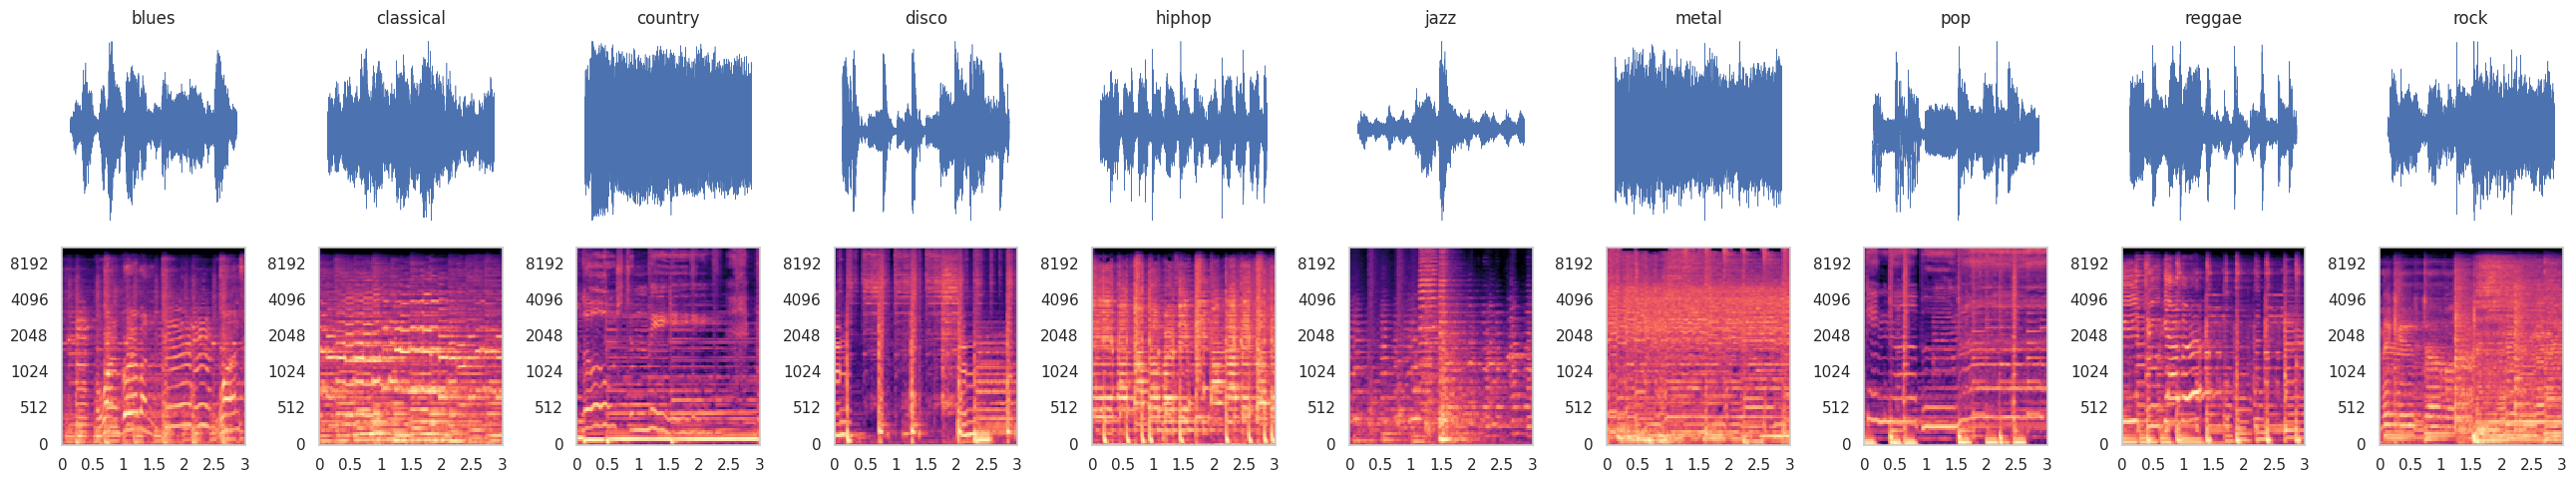

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(26, 5))
for j, g in enumerate(GENRES):
    p = df_tracks[df_tracks.genre == g].path.iloc[0]
    y_, _ = librosa.load(p, sr=SR, duration=3)
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y_, sr=SR, n_mels=N_MELS), ref=np.max)
    axes[0, j].plot(y_, lw=0.4); axes[0, j].set_title(g); axes[0, j].axis("off")
    librosa.display.specshow(S, sr=SR, hop_length=512, x_axis="time", y_axis="mel", ax=axes[1, j])
    axes[1, j].set_xlabel(""); axes[1, j].set_ylabel("")
plt.tight_layout(); plt.show()

## 2. Feature extraction (one pass, two outputs)
For every track we load 30 s of audio, cut it into ten 3 s segments, and for each segment compute

* **Tabular vector (60 features):** mean/variance of chroma, RMS, spectral centroid, bandwidth, rolloff, zero-crossing rate; 7 spectral-contrast means; 20 MFCC means and 20 MFCC variances; the track tempo.
* **Mel-spectrogram image:** 128 mel bins x 128 frames, converted to dB (80 dB range) and stored as `uint8` (0-255) to keep memory small.

This takes a few minutes with all CPU cores; results are cached in `gtzan_cache.npz`.

In [5]:
FEATURE_NAMES = (
    ["chroma_mean", "chroma_var", "rms_mean", "rms_var", "centroid_mean", "centroid_var",
     "bandwidth_mean", "bandwidth_var", "rolloff_mean", "rolloff_var", "zcr_mean", "zcr_var"]
    + [f"contrast{i}_mean" for i in range(1, 8)]
    + [f"mfcc{i}_mean" for i in range(1, 21)]
    + [f"mfcc{i}_var" for i in range(1, 21)]
    + ["tempo"]
)

def process_track(path):
    """Return (features[N_SEGS, 60], mels[N_SEGS, 128, 128] uint8) or None if the file is unreadable."""
    try:
        y, _ = librosa.load(path, sr=SR, duration=SEG_SECONDS * N_SEGS)
    except Exception as e:
        return None
    need = SEG_LEN * N_SEGS
    y = np.pad(y, (0, max(0, need - len(y))))[:need]

    onset = librosa.onset.onset_strength(y=y, sr=SR)
    tempo = float(np.atleast_1d(librosa.feature.tempo(onset_envelope=onset, sr=SR))[0])

    feats, mels = [], []
    for i in range(N_SEGS):
        seg = y[i * SEG_LEN:(i + 1) * SEG_LEN]
        S = np.abs(librosa.stft(seg, n_fft=N_FFT, hop_length=HOP))
        mel = librosa.feature.melspectrogram(S=S ** 2, sr=SR, n_mels=N_MELS)
        mel_db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)

        mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel), n_mfcc=20)
        chroma = librosa.feature.chroma_stft(S=S, sr=SR)
        cent = librosa.feature.spectral_centroid(S=S, sr=SR)
        bw = librosa.feature.spectral_bandwidth(S=S, sr=SR)
        roll = librosa.feature.spectral_rolloff(S=S, sr=SR)
        zcr = librosa.feature.zero_crossing_rate(seg, hop_length=HOP)
        rms = librosa.feature.rms(S=S)
        contrast = librosa.feature.spectral_contrast(S=S, sr=SR)

        vec = [chroma.mean(), chroma.var(), rms.mean(), rms.var(), cent.mean(), cent.var(),
               bw.mean(), bw.var(), roll.mean(), roll.var(), zcr.mean(), zcr.var()]
        vec += list(contrast.mean(axis=1)) + list(mfcc.mean(axis=1)) + list(mfcc.var(axis=1)) + [tempo]
        feats.append(vec)

        img = ((mel_db[:, :N_FRAMES] + 80.0) / 80.0 * 255.0).clip(0, 255).astype(np.uint8)
        mels.append(img)
    return np.asarray(feats, dtype=np.float32), np.stack(mels)

CACHE = "gtzan_cache.npz"
if os.path.exists(CACHE):
    d = np.load(CACHE)
    X_tab, X_img, y_seg, tid_seg, track_labels = d["X_tab"], d["X_img"], d["y_seg"], d["tid_seg"], d["track_labels"]
    print("Loaded cache")
else:
    t0 = time.time()
    results = Parallel(n_jobs=-1, verbose=5)(delayed(process_track)(p) for p in df_tracks.path)
    ok = [i for i, r in enumerate(results) if r is not None]
    bad = [df_tracks.path[i] for i, r in enumerate(results) if r is None]
    print(f"Done in {time.time()-t0:.0f}s. Skipped {len(bad)} unreadable file(s): {[os.path.basename(b) for b in bad]}")
    X_tab = np.concatenate([results[i][0] for i in ok])
    X_img = np.concatenate([results[i][1] for i in ok])[..., None]            # (N, 128, 128, 1) uint8
    track_labels = df_tracks.label.values[ok]                                  # one label per kept track
    y_seg = np.repeat(track_labels, N_SEGS)
    tid_seg = np.repeat(np.arange(len(ok)), N_SEGS)                            # track id for every segment
    np.savez_compressed(CACHE, X_tab=X_tab, X_img=X_img, y_seg=y_seg, tid_seg=tid_seg, track_labels=track_labels)

print("tabular:", X_tab.shape, "| images:", X_img.shape, X_img.dtype, "| tracks:", len(track_labels))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:    7.1s
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:   20.8s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:   44.5s
[Parallel(n_jobs=-1)]: Done 284 tasks      | elapsed:  1.3min
[Parallel(n_jobs=-1)]: Done 446 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 644 tasks      | elapsed:  2.8min
[Parallel(n_jobs=-1)]: Done 878 tasks      | elapsed:  3.8min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  4.3min finished


Done in 259s. Skipped 1 unreadable file(s): ['jazz.00054.wav']
tabular: (9990, 60) | images: (9990, 128, 128, 1) uint8 | tracks: 999


## 3. Track-level train / validation / test split (70 / 15 / 15)
Stratified by genre, performed on **tracks**; all ten segments of a track stay together.

In [6]:
n_tracks = len(track_labels)
all_tracks = np.arange(n_tracks)
tr_t, tmp_t = train_test_split(all_tracks, test_size=0.30, stratify=track_labels, random_state=SEED)
va_t, te_t = train_test_split(tmp_t, test_size=0.50, stratify=track_labels[tmp_t], random_state=SEED)

idx_tr = np.where(np.isin(tid_seg, tr_t))[0]
idx_va = np.where(np.isin(tid_seg, va_t))[0]
idx_te = np.where(np.isin(tid_seg, te_t))[0]
print(f"tracks  train/val/test: {len(tr_t)}/{len(va_t)}/{len(te_t)}")
print(f"segments train/val/test: {len(idx_tr)}/{len(idx_va)}/{len(idx_te)}")

# sanity: no track in more than one split
assert not (set(tid_seg[idx_tr]) & set(tid_seg[idx_va])) and not (set(tid_seg[idx_tr]) & set(tid_seg[idx_te]))

# ---- helpers shared by all approaches ----
RESULTS = []

def track_level(probs, idx):
    """Average segment probabilities per track -> (true, pred) at track level."""
    d = pd.DataFrame(probs); d["tid"] = tid_seg[idx]
    mean = d.groupby("tid").mean()
    pred = mean.values.argmax(1)
    true = track_labels[mean.index.values]
    return true, pred

def evaluate(name, approach, p_val, p_test):
    seg_val = accuracy_score(y_seg[idx_va], p_val.argmax(1))
    tv, pv = track_level(p_val, idx_va)
    seg_te = accuracy_score(y_seg[idx_te], p_test.argmax(1))
    tt, pt = track_level(p_test, idx_te)
    RESULTS.append(dict(model=name, approach=approach, val_segment_acc=seg_val, val_track_acc=accuracy_score(tv, pv),
                        test_segment_acc=seg_te, test_track_acc=accuracy_score(tt, pt)))
    print(f"{name:28s} val seg {seg_val:.3f} | val track {accuracy_score(tv, pv):.3f} || "
          f"test seg {seg_te:.3f} | test track {accuracy_score(tt, pt):.3f}")
    return tt, pt

def plot_cm(true, pred, title):
    cm = confusion_matrix(true, pred, normalize="true")
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=GENRES, yticklabels=GENRES, cbar=False)
    plt.title(title); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()

tracks  train/val/test: 699/150/150
segments train/val/test: 6990/1500/1500


## 4. Approach A - Tabular features + classical ML
Everything goes through a `StandardScaler` (important for kNN / SVM / LR / MLP).

In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)),
    "kNN (k=7)":           make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights="distance")),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(C=10, gamma="scale", probability=True, random_state=SEED)),
    "Random Forest":       RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED),
    "MLP":                 make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256, 128), alpha=1e-3,
                                         early_stopping=True, max_iter=300, random_state=SEED)),
}
tab_preds = {}
for name, m in models.items():
    m.fit(X_tab[idx_tr], y_seg[idx_tr])
    pv, pt = m.predict_proba(X_tab[idx_va]), m.predict_proba(X_tab[idx_te])
    tab_preds[name] = evaluate("Tabular - " + name, "A: tabular", pv, pt)

Tabular - Logistic Regression val seg 0.743 | val track 0.787 || test seg 0.699 | test track 0.787
Tabular - kNN (k=7)          val seg 0.678 | val track 0.793 || test seg 0.661 | test track 0.753
Tabular - SVM (RBF)          val seg 0.741 | val track 0.813 || test seg 0.730 | test track 0.800
Tabular - Random Forest      val seg 0.733 | val track 0.820 || test seg 0.717 | test track 0.807
Tabular - HistGradientBoosting val seg 0.769 | val track 0.833 || test seg 0.747 | test track 0.807
Tabular - MLP                val seg 0.755 | val track 0.833 || test seg 0.701 | test track 0.767


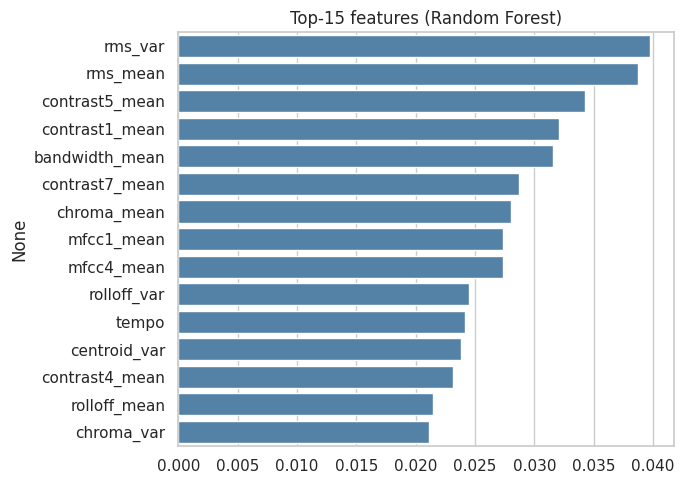

In [8]:
# Which features matter? (Random Forest importances)
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 5)); sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Top-15 features (Random Forest)"); plt.tight_layout(); plt.show()

## 5. Approach B - CNN from scratch on mel-spectrograms
A small 4-block CNN. Training uses **SpecAugment-style time / frequency masking** to reduce over-fitting (only 700 training tracks!).

In [9]:
BATCH = 64

def _mask(x, length, max_w, axis):
    w = tf.random.uniform([], 0, max_w + 1, dtype=tf.int32)
    s = tf.random.uniform([], 0, length - w + 1, dtype=tf.int32)
    r = tf.range(length)
    keep = 1.0 - tf.cast((r >= s) & (r < s + w), tf.float32)
    return x * tf.reshape(keep, [length, 1, 1] if axis == 0 else [1, length, 1])

def augment(x, y):
    x = _mask(x, N_MELS, 16, axis=0)      # frequency mask
    x = _mask(x, N_FRAMES, 20, axis=1)    # time mask
    return x, y

def make_ds(idx, train=False):
    ds = tf.data.Dataset.from_tensor_slices((X_img[idx], y_seg[idx]))
    if train:
        ds = ds.shuffle(4096, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

ds_tr, ds_va, ds_te = make_ds(idx_tr, True), make_ds(idx_va), make_ds(idx_te)

def callbacks(patience=8):
    return [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)]

def build_cnn():
    inp = keras.Input((N_MELS, N_FRAMES, 1))
    x = layers.Rescaling(1 / 255.0)(inp)
    for f in (32, 64, 128, 256):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x); x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(0.4)(x)
    return keras.Model(inp, layers.Dense(len(GENRES), activation="softmax")(x), name="cnn_scratch")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "cnn_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             

 Total params: 423,466 (1.62 MB)

 Trainable params: 422,506 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [10]:
hist_cnn = cnn.fit(ds_tr, validation_data=ds_va, epochs=60, callbacks=callbacks(10), verbose=2)

Epoch 1/60
110/110 - 40s - 362ms/step - accuracy: 0.3432 - loss: 1.8399 - val_accuracy: 0.1000 - val_loss: 4.1136 - learning_rate: 0.0010
Epoch 2/60
110/110 - 5s - 49ms/step - accuracy: 0.4162 - loss: 1.5860 - val_accuracy: 0.1000 - val_loss: 4.8598 - learning_rate: 0.0010
Epoch 3/60
110/110 - 5s - 48ms/step - accuracy: 0.4750 - loss: 1.4458 - val_accuracy: 0.1000 - val_loss: 3.8087 - learning_rate: 0.0010
Epoch 4/60
110/110 - 5s - 49ms/step - accuracy: 0.5368 - loss: 1.3050 - val_accuracy: 0.1900 - val_loss: 2.9741 - learning_rate: 0.0010
Epoch 5/60
110/110 - 5s - 49ms/step - accuracy: 0.5461 - loss: 1.2655 - val_accuracy: 0.3260 - val_loss: 2.6713 - learning_rate: 0.0010
Epoch 6/60
110/110 - 5s - 49ms/step - accuracy: 0.5721 - loss: 1.1952 - val_accuracy: 0.4733 - val_loss: 1.6243 - learning_rate: 0.0010
Epoch 7/60
110/110 - 5s - 49ms/step - accuracy: 0.6080 - loss: 1.1209 - val_accuracy: 0.4353 - val_loss: 1.7157 - learning_rate: 0.0010
Epoch 8/60
110/110 - 5s - 49ms/step - accuracy

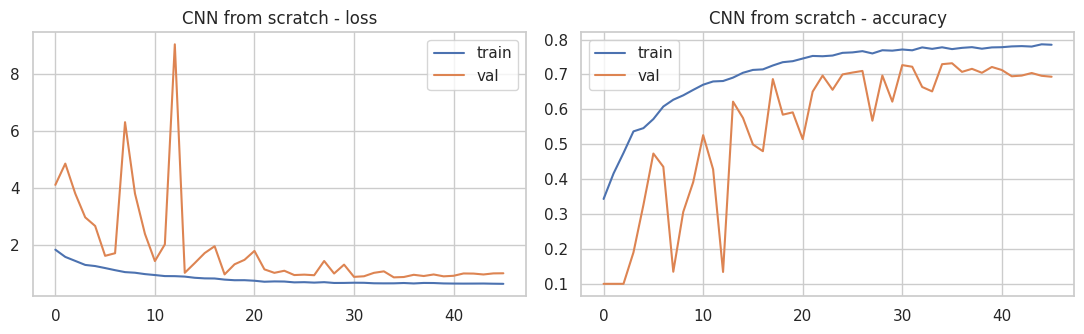

CNN from scratch             val seg 0.732 | val track 0.767 || test seg 0.710 | test track 0.780


In [11]:
def plot_history(histories, title):
    h = {}
    for hh in histories:
        for k, v in hh.history.items():
            h.setdefault(k, []).extend(v)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title(title + " - loss"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title(title + " - accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history([hist_cnn], "CNN from scratch")
pv, pt = cnn.predict(ds_va, verbose=0), cnn.predict(ds_te, verbose=0)
cnn_true, cnn_pred = evaluate("CNN from scratch", "B: CNN (spectrogram)", pv, pt)

## 6. Approach C - Transfer learning (ImageNet-pretrained backbone)
Idea: low-level filters learned on ImageNet (edges, textures, repeated patterns) also help on spectrograms.

1. Replicate the 1-channel spectrogram to 3 channels and apply the preprocessing the backbone expects.
2. **Stage 1:** freeze the backbone, train only the new classification head.
3. **Stage 2:** unfreeze the top of the backbone (BatchNorm layers stay frozen) and fine-tune with a small learning rate.

Change `BACKBONE` to try other networks.

In [12]:
BACKBONE = "MobileNetV2"     # "MobileNetV2" or "EfficientNetB0"

def build_transfer(backbone=BACKBONE):
    inp = keras.Input((N_MELS, N_FRAMES, 1))
    x = layers.Concatenate()([inp, inp, inp])                       # 1 -> 3 channels
    if backbone == "MobileNetV2":
        x = layers.Rescaling(1 / 127.5, offset=-1)(x)               # expects [-1, 1]
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=(N_MELS, N_FRAMES, 3))
    elif backbone == "EfficientNetB0":                              # expects raw 0-255 (has its own rescaling)
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(N_MELS, N_FRAMES, 3))
    else:
        raise ValueError(backbone)
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(GENRES), activation="softmax")(x)
    return keras.Model(inp, out, name=f"transfer_{backbone}"), base

tl, base = build_transfer()
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Stage 1 - train head only")
hist_tl1 = tl.fit(ds_tr, validation_data=ds_va, epochs=15, callbacks=callbacks(5), verbose=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Stage 1 - train head only
Epoch 1/15
110/110 - 28s - 257ms/step - accuracy: 0.3299 - loss: 1.9344 - val_accuracy: 0.4493 - val_loss: 1.5072 - learning_rate: 0.0010
Epoch 2/15
110/110 - 3s - 24ms/step - accuracy: 0.4269 - loss: 1.6003 - val_accuracy: 0.5033 - val_loss: 1.3480 - learning_rate: 0.0010
Epoch 3/15
110/110 - 3s - 23ms/step - accuracy: 0.4674 - loss: 1.5206 - val_accuracy: 0.5667 - val_loss: 1.2909 - learning_rate: 0.0010
Epoch 4/15
110/110 - 2s - 23ms/step - accuracy: 0.4867 - loss: 1.4524 - val_accuracy: 0.5640 - val_loss: 1.2792 - learning_rate: 0.0010
Epoch 5/15
110/110 - 3s - 24ms/step - accuracy: 0.4980 - loss: 1.4110 - val_accuracy: 0.5707 - val_loss: 1.2187 - learning_rate: 0.0010
Epoch 6/15
110/110 - 3s - 24ms/step - accuracy: 0.5004 - loss: 1.3915 - val_accuracy: 0.5793 - val_loss: 1.1567 - learning_rate: 0.0010
Epoch 7/15
110/110 - 3s - 25ms/step - accuracy: 0.5173 - loss: 1.3469 - val_accuracy: 0.5780 - val_loss: 1.

In [13]:
# Stage 2 - fine-tune the top of the backbone
N_UNFREEZE = 60
base.trainable = True
for layer in base.layers[:-N_UNFREEZE]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False                       # keep BN statistics stable

tl.compile(optimizer=keras.optimizers.Adam(3e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Stage 2 - fine-tuning, trainable weights:", sum(int(np.prod(w.shape)) for w in tl.trainable_weights))
hist_tl2 = tl.fit(ds_tr, validation_data=ds_va, epochs=40, callbacks=callbacks(8), verbose=2)

Stage 2 - fine-tuning, trainable weights: 2097034
Epoch 1/40
110/110 - 43s - 393ms/step - accuracy: 0.5554 - loss: 1.2676 - val_accuracy: 0.6173 - val_loss: 1.0511 - learning_rate: 3.0000e-05
Epoch 2/40
110/110 - 4s - 33ms/step - accuracy: 0.5860 - loss: 1.1488 - val_accuracy: 0.6140 - val_loss: 1.0129 - learning_rate: 3.0000e-05
Epoch 3/40
110/110 - 4s - 33ms/step - accuracy: 0.6266 - loss: 1.0684 - val_accuracy: 0.6527 - val_loss: 0.9365 - learning_rate: 3.0000e-05
Epoch 4/40
110/110 - 4s - 32ms/step - accuracy: 0.6329 - loss: 1.0413 - val_accuracy: 0.6427 - val_loss: 0.9603 - learning_rate: 3.0000e-05
Epoch 5/40
110/110 - 4s - 33ms/step - accuracy: 0.6409 - loss: 1.0176 - val_accuracy: 0.6600 - val_loss: 0.9313 - learning_rate: 3.0000e-05
Epoch 6/40
110/110 - 4s - 32ms/step - accuracy: 0.6607 - loss: 0.9557 - val_accuracy: 0.6440 - val_loss: 1.0215 - learning_rate: 3.0000e-05
Epoch 7/40
110/110 - 4s - 35ms/step - accuracy: 0.6662 - loss: 0.9450 - val_accuracy: 0.7080 - val_loss: 0.8

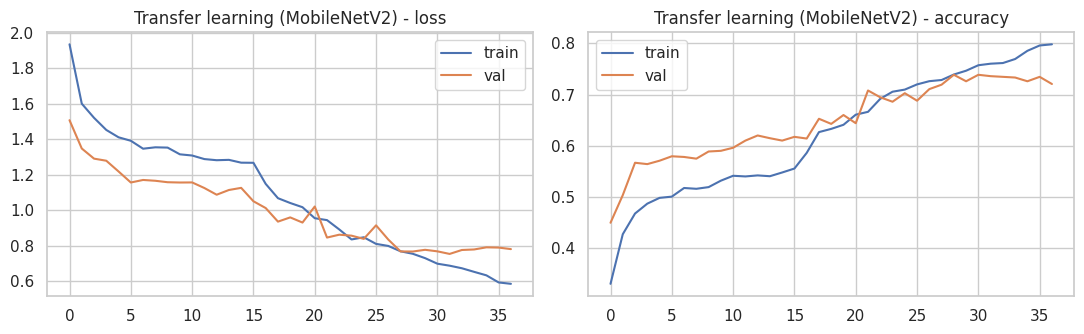

Transfer (MobileNetV2, fine-tuned) val seg 0.739 | val track 0.813 || test seg 0.721 | test track 0.773


In [14]:
plot_history([hist_tl1, hist_tl2], f"Transfer learning ({BACKBONE})")
pv, pt = tl.predict(ds_va, verbose=0), tl.predict(ds_te, verbose=0)
tl_true, tl_pred = evaluate(f"Transfer ({BACKBONE}, fine-tuned)", "C: transfer learning", pv, pt)

## 7. Comparison

,model,approach,val_segment_acc,val_track_acc,test_segment_acc,test_track_acc
0,Tabular - Random Forest,A: tabular,0.733,0.820,0.717,0.807
1,Tabular - HistGradientBoosting,A: tabular,0.769,0.833,0.747,0.807
2,Tabular - SVM (RBF),A: tabular,0.741,0.813,0.730,0.800
3,Tabular - Logistic Regression,A: tabular,0.743,0.787,0.699,0.787
4,CNN from scratch,B: CNN (spectrogram),0.732,0.767,0.710,0.780
5,"Transfer (MobileNetV2, fine-tuned)",C: transfer learning,0.739,0.813,0.721,0.773
6,Tabular - MLP,A: tabular,0.755,0.833,0.701,0.767
7,Tabular - kNN (k=7),A: tabular,0.678,0.793,0.661,0.753


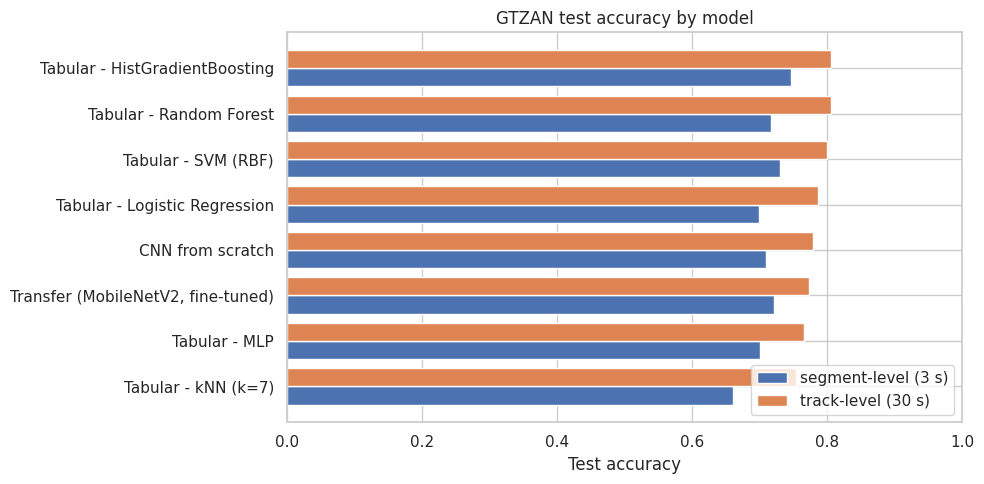

In [15]:
res = pd.DataFrame(RESULTS).sort_values("test_track_acc", ascending=False).reset_index(drop=True)
display(res.style.format({c: "{:.3f}" for c in res.columns if "acc" in c}).background_gradient(subset=["test_track_acc"], cmap="Greens"))

fig, ax = plt.subplots(figsize=(10, 5))
order = res.sort_values("test_track_acc").reset_index(drop=True)
y_pos = np.arange(len(order))
ax.barh(y_pos - 0.2, order.test_segment_acc, height=0.4, label="segment-level (3 s)")
ax.barh(y_pos + 0.2, order.test_track_acc, height=0.4, label="track-level (30 s)")
ax.set_yticks(y_pos); ax.set_yticklabels(order.model); ax.set_xlim(0, 1); ax.set_xlabel("Test accuracy"); ax.legend(loc="lower right")
ax.set_title("GTZAN test accuracy by model"); plt.tight_layout(); plt.show()

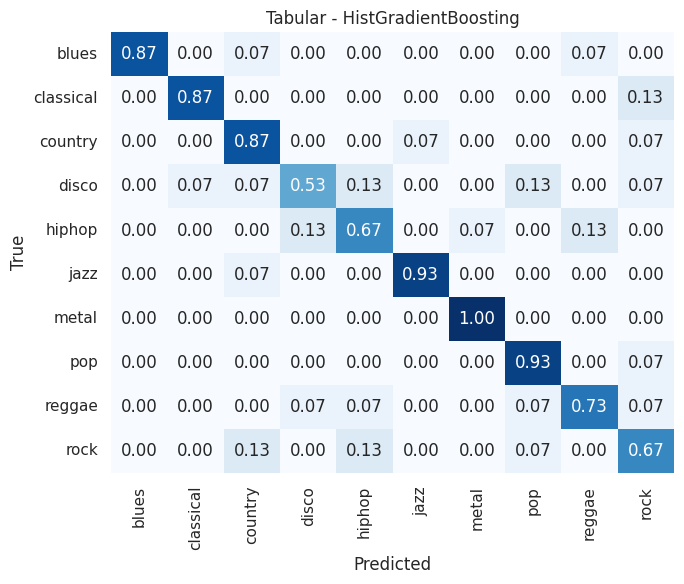

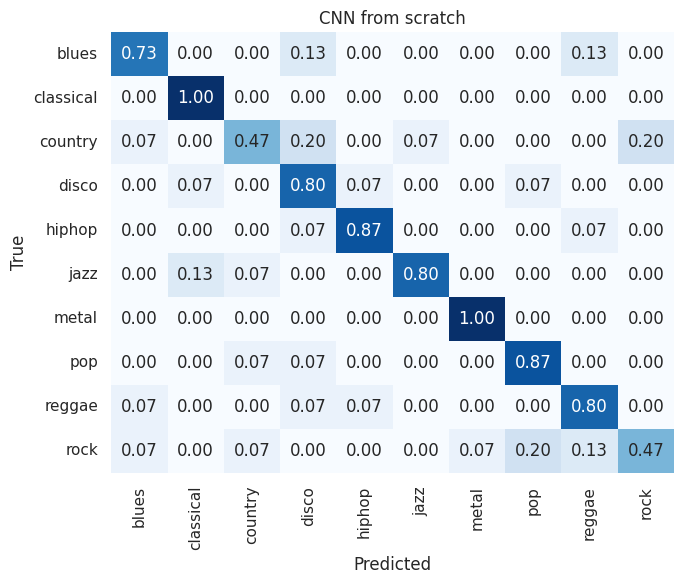

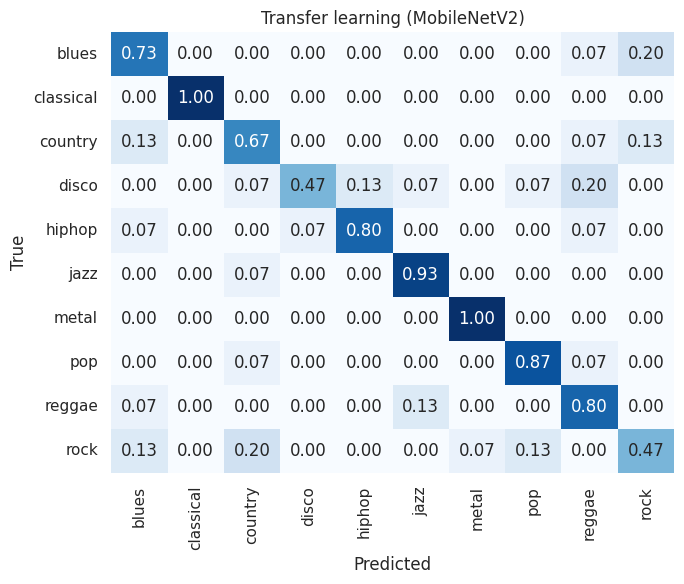

              precision    recall  f1-score   support

       blues      0.647     0.733     0.688        15
   classical      1.000     1.000     1.000        15
     country      0.625     0.667     0.645        15
       disco      0.875     0.467     0.609        15
      hiphop      0.857     0.800     0.828        15
        jazz      0.824     0.933     0.875        15
       metal      0.938     1.000     0.968        15
         pop      0.812     0.867     0.839        15
      reggae      0.632     0.800     0.706        15
        rock      0.583     0.467     0.519        15

    accuracy                          0.773       150
   macro avg      0.779     0.773     0.767       150
weighted avg      0.779     0.773     0.767       150



In [16]:
# Confusion matrices (track-level, test set) for the best tabular model, the CNN and the transfer model
best_tab = max([r for r in RESULTS if r["approach"] == "A: tabular"], key=lambda r: r["val_track_acc"])["model"].replace("Tabular - ", "")
t_true, t_pred = tab_preds[best_tab]
plot_cm(t_true, t_pred, f"Tabular - {best_tab}")
plot_cm(cnn_true, cnn_pred, "CNN from scratch")
plot_cm(tl_true, tl_pred, f"Transfer learning ({BACKBONE})")
print(classification_report(tl_true, tl_pred, target_names=GENRES, digits=3))

### How to read the results
* **Segment vs track accuracy:** track-level is almost always higher because averaging 10 segments smooths out noisy 3 s predictions.
* **Tabular vs CNN:** hand-crafted features with an SVM/boosting model are a strong baseline on a small dataset like GTZAN; a CNN from scratch has to learn everything from ~700 tracks and can over-fit.
* **Transfer learning** usually gives the best spectrogram model because the backbone starts with useful pre-trained filters, and fine-tuning adapts them to audio.
* **Typical confusions:** rock <-> metal, country <-> blues, disco <-> pop, jazz <-> classical. Genre labels in GTZAN overlap musically, and the dataset is known to contain some mislabeled and duplicated tracks, so ~90 % is already near its practical ceiling.
* The test set contains only ~150 tracks, so one track is about 0.7 %. Differences of 1-2 points are within noise: rerun with several seeds or use cross-validation before drawing strong conclusions.

### Ideas to go further
* Try `BACKBONE = "EfficientNetB0"` or a larger input (e.g. 224 x 224 spectrograms).
* Pre-trained *audio* models (YAMNet, PANNs, AST) instead of image backbones.
* Ensemble the tabular and image models by averaging their probabilities.
* Stratified group k-fold over tracks for more reliable estimates.

## 8. Predict the genre of any audio file

In [17]:
def predict_genre(path, model=None, top_k=3):
    """Cut the clip into 3 s segments, classify each with the CNN-type model, average the probabilities."""
    model = model or tl
    y, _ = librosa.load(path, sr=SR)
    n = max(1, len(y) // SEG_LEN)
    segs = []
    for i in range(n):
        seg = y[i * SEG_LEN:(i + 1) * SEG_LEN]
        seg = np.pad(seg, (0, SEG_LEN - len(seg)))
        mel = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
        db = librosa.power_to_db(mel, ref=np.max, top_db=80.0)[:, :N_FRAMES]
        segs.append(((db + 80) / 80 * 255).clip(0, 255)[..., None])
    p = model.predict(np.stack(segs).astype("float32"), verbose=0).mean(axis=0)
    return [(GENRES[i], float(p[i])) for i in np.argsort(p)[::-1][:top_k]]

# Example (uses a test track):
example = df_tracks.path[df_tracks.label == 0].iloc[0]
print(os.path.basename(example), "->", predict_genre(example))

blues.00000.wav -> [('blues', 0.58153235912323), ('jazz', 0.31756868958473206), ('rock', 0.03614865988492966)]


In [18]:
# Save models and results
cnn.save("cnn_scratch.keras"); tl.save("transfer_model.keras")
res.to_csv("results.csv", index=False)
print("saved: cnn_scratch.keras, transfer_model.keras, results.csv")

saved: cnn_scratch.keras, transfer_model.keras, results.csv
